In [1]:
!git clone https://github.com/INFO523-S24/ex-06.git
%cd /kaggle/working/ex-06
!ls

Cloning into 'ex-06'...
remote: Enumerating objects: 46, done.
remote: Counting objects: 100% (46/46), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 46 (delta 11), reused 25 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (46/46), 1.36 MiB | 9.25 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/kaggle/working/ex-06
check_allowed_files.py	data  ex-06.ipynb  README.md  requirements.txt


In [2]:
import os

os.listdir("data")

['ADD_DATA_HERE', 'spam.csv']

In [3]:
import pandas as pd

spam = pd.read_csv("data/spam.csv")

print("Veri boyutu:", spam.shape)
display(spam.head())
spam.info()

Veri boyutu: (4601, 7)


,crl.tot,dollar,bang,money,n000,make,yesno
0,278,0.000,0.778,0.00,0.00,0.00,y
1,1028,0.180,0.372,0.43,0.43,0.21,y
2,2259,0.184,0.276,0.06,1.16,0.06,y
3,191,0.000,0.137,0.00,0.00,0.00,y
4,191,0.000,0.135,0.00,0.00,0.00,y


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crl.tot  4601 non-null   int64  
 1   dollar   4601 non-null   float64
 2   bang     4601 non-null   float64
 3   money    4601 non-null   float64
 4   n000     4601 non-null   float64
 5   make     4601 non-null   float64
 6   yesno    4601 non-null   object 
dtypes: float64(5), int64(1), object(1)
memory usage: 251.7+ KB


In [4]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

# "n" ve "y" etiketlerini sayılara çevir
encoder = LabelEncoder()
spam["yesno"] = encoder.fit_transform(spam["yesno"])

print("Etiket eşlemesi:", dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))

# Özellikler ve hedef
X = spam.drop("yesno", axis=1)
y = spam["yesno"]

# Veriyi eğitim ve test kümelerine ayır
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# PCA: özellikleri iki bileşene indir
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Eğitim kümesi:", X_train_pca.shape)
print("Test kümesi:", X_test_pca.shape)
print("PCA'nın açıkladığı varyans oranı:", pca.explained_variance_ratio_)

Etiket eşlemesi: {'n': np.int64(0), 'y': np.int64(1)}
Eğitim kümesi: (3680, 2)
Test kümesi: (921, 2)
PCA'nın açıkladığı varyans oranı: [9.99996219e-01 2.28286897e-06]


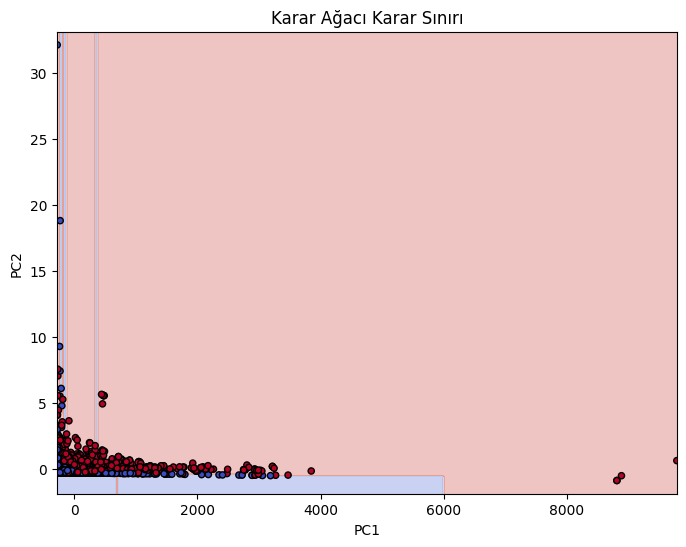

In [5]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import numpy as np

# Karar Ağacını eğit
dtree = DecisionTreeClassifier(random_state=42)
dtree.fit(X_train_pca, y_train)

def decisionplot(model, X, y):
    x_min, x_max = X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1
    y_min, y_max = X.iloc[:, 1].min() - 1, X.iloc[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    regions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, regions, alpha=0.3, cmap="coolwarm")
    plt.scatter(
        X.iloc[:, 0], X.iloc[:, 1],
        c=np.asarray(y), cmap="coolwarm",
        edgecolor="k", s=20
    )
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("Karar Ağacı Karar Sınırı")
    plt.show()

X_train_plot = pd.DataFrame(X_train_pca, columns=["PC1", "PC2"])
decisionplot(dtree, X_train_plot, y_train)

Accuracy:  0.809
Precision: 0.809
Recall:    0.809
F1 Score:  0.807
AUC-ROC:   0.769


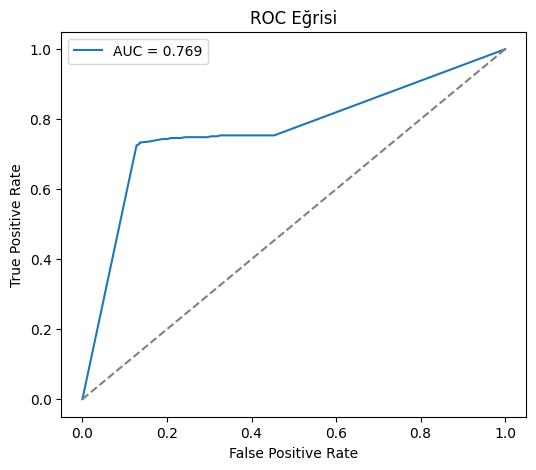

In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt

# Test kümesindeki sınıf tahminleri
predictions = dtree.predict(X_test_pca)

# Spam (1) sınıfı için tahmin olasılığı
spam_index = list(dtree.classes_).index(1)
spam_probabilities = dtree.predict_proba(X_test_pca)[:, spam_index]

# Performans metrikleri
print(f"Accuracy:  {accuracy_score(y_test, predictions):.3f}")
print(f"Precision: {precision_score(y_test, predictions, average='weighted'):.3f}")
print(f"Recall:    {recall_score(y_test, predictions, average='weighted'):.3f}")
print(f"F1 Score:  {f1_score(y_test, predictions, average='weighted'):.3f}")
print(f"AUC-ROC:   {roc_auc_score(y_test, spam_probabilities):.3f}")

# ROC eğrisi
fpr, tpr, thresholds = roc_curve(y_test, spam_probabilities)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, spam_probabilities):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Eğrisi")
plt.legend()
plt.show()

In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

print(classification_report(
    y_test,
    predictions,
    target_names=["Spam değil (n)", "Spam (y)"],
    digits=3
))

cm = confusion_matrix(y_test, predictions)
display(pd.DataFrame(
    cm,
    index=["Gerçek: Spam değil", "Gerçek: Spam"],
    columns=["Tahmin: Spam değil", "Tahmin: Spam"]
))

                precision    recall  f1-score   support

Spam değil (n)      0.812     0.870     0.840       531
      Spam (y)      0.804     0.726     0.763       390

      accuracy                          0.809       921
     macro avg      0.808     0.798     0.801       921
  weighted avg      0.809     0.809     0.807       921



,Tahmin: Spam değil,Tahmin: Spam
Gerçek: Spam değil,462,69
Gerçek: Spam,107,283


In [8]:
# Aynı Karar Ağacı'nı PCA uygulanmamış 6 özellik ile eğit
dtree_original = DecisionTreeClassifier(random_state=42)
dtree_original.fit(X_train, y_train)

predictions_original = dtree_original.predict(X_test)
probabilities_original = dtree_original.predict_proba(X_test)[:, 1]

print(f"Accuracy:  {accuracy_score(y_test, predictions_original):.3f}")
print(f"Precision: {precision_score(y_test, predictions_original, average='weighted'):.3f}")
print(f"Recall:    {recall_score(y_test, predictions_original, average='weighted'):.3f}")
print(f"F1 Score:  {f1_score(y_test, predictions_original, average='weighted'):.3f}")
print(f"AUC-ROC:   {roc_auc_score(y_test, probabilities_original):.3f}")

Accuracy:  0.841
Precision: 0.842
Recall:    0.841
F1 Score:  0.840
AUC-ROC:   0.810


Karar Ağacı modeli, PCA ile altı özellik iki bileşene indirildiğinde 0,809 doğruluk ve 0,769 AUC-ROC elde etmiştir. PCA kullanılmadan eğitilen modelin doğruluğu 0,841, AUC-ROC değeri ise 0,810 olmuştur. Bu karşılaştırmada PCA, karar sınırını iki boyutlu grafikte görmeyi sağlamış; ancak tahmin performansı daha düşük çıkmıştır. PCA grafiğinde varyansın neredeyse tamamı ilk bileşende toplanmıştır. Özellikler PCA öncesinde standartlaştırılmadığı için farklı ölçeklerdeki değerler bu sonucu etkilemiş olabilir. Model, 390 spam e-postanın 283’ünü doğru tespit etmiş, 107’sini kaçırmıştır; spam recall değeri 0,726’dır. Spam e-postaları kaçırmamak önemliyse recall, normal e-postaları yanlışlıkla spam olarak işaretlememek önemliyse precision dikkate alınmalıdır.